# Topic 5 figures: choice over time and under uncertainty

Static figures for `slides/05_time-and-uncertainty/deck.qmd`. Run all cells; each saves a PNG
into the deck's `figs/` folder.

One set of numbers runs through the whole topic: log utility, $\delta = 1$, $\pi = 1/2$.
The **borrower** starts with $(m_1, m_2) = (20, 80)$ and the **saver** with $(80, 20)$.
At $r = 0$ both consume $(50, 50)$. At $r = 25\%$ the borrower moves to $(42, 52.5)$ and the
saver to $(48, 60)$. Under uncertainty the same $(20, 80)$ is income in drought and in rain.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"
GREY = "#8a8a8a"
RED = "#c83232"
plt.rcParams.update({"font.family": "serif", "font.size": 12,
                     "axes.edgecolor": "#333333", "axes.labelcolor": "#222222",
                     "axes.spines.top": False, "axes.spines.right": False})
FIGDIR = Path("../slides/05_time-and-uncertainty/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

def ic(ax, k, lo=8, hi=125, **kw):
    """Log-utility indifference curve c1 * c2 = k."""
    x = np.linspace(lo, hi, 400)
    ax.plot(x, k / x, **kw)

def budget(ax, m1, m2, r, **kw):
    """Budget line through the endowment with slope -(1+r)."""
    W = m1 + m2 / (1 + r)
    ax.plot([0, W], [W * (1 + r), 0], **kw)

def dot(ax, x, y, label, color=NAVY, dx=8, dy=8, ha="left", **kw):
    ax.plot(x, y, "o", color=color, ms=9, zorder=6)
    ax.annotate(label, (x, y), textcoords="offset points", xytext=(dx, dy),
                fontsize=11, color=color, ha=ha, **kw)

def frame(ax, xl, yl, lim=110, ylim=None):
    ax.set_xlim(0, lim); ax.set_ylim(0, ylim or lim)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_aspect("equal")

T1, T2 = "$c_1$ (today)", "$c_2$ (tomorrow)"


## 1. The intertemporal budget line (borrower, r = 25%)

saved ..\slides\05_time-and-uncertainty\figs\intertemporal-budget.png


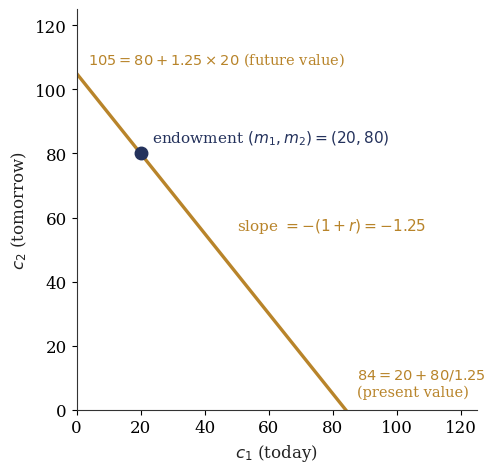

In [2]:
fig, ax = plt.subplots(figsize=(6.0, 5.2))
budget(ax, 20, 80, 0.25, color=AMBER, lw=2.4)
dot(ax, 20, 80, "endowment $(m_1, m_2) = (20, 80)$")
ax.annotate("$84 = 20 + 80/1.25$\n(present value)", (84, 0), textcoords="offset points",
            xytext=(8, 10), fontsize=10.5, ha="left", color=AMBER)
ax.annotate("$105 = 80 + 1.25 \\times 20$ (future value)", (0, 105), textcoords="offset points",
            xytext=(8, 4), fontsize=10.5, va="bottom", color=AMBER)
ax.annotate("slope $= -(1+r) = -1.25$", (50, 56), fontsize=11, color=AMBER)
frame(ax, T1, T2, lim=125)
savefig(fig, "intertemporal-budget.png")
plt.show()

## 2. Borrower and saver at r = 0

saved ..\slides\05_time-and-uncertainty\figs\borrower-saver.png


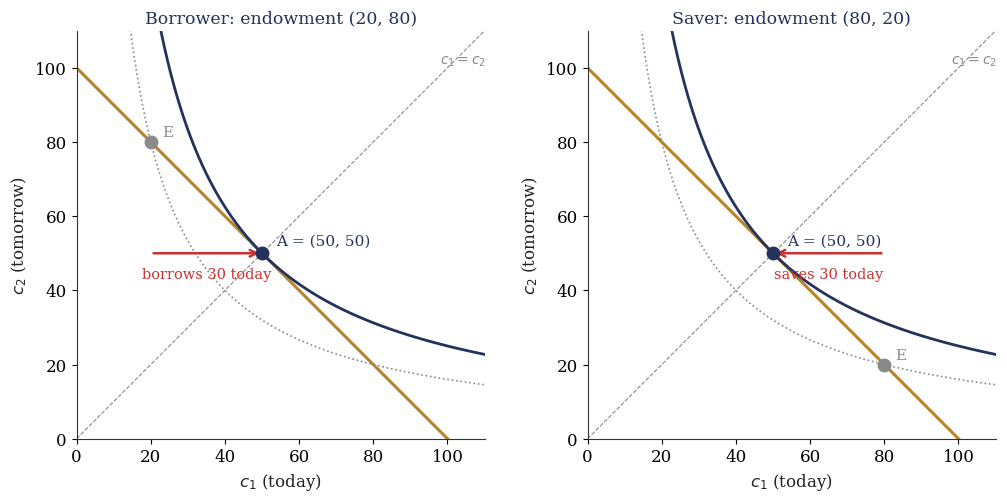

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.0))
for ax, (m1, m2), title, verb in [(axes[0], (20, 80), "Borrower: endowment (20, 80)", "borrows 30 today"),
                                  (axes[1], (80, 20), "Saver: endowment (80, 20)", "saves 30 today")]:
    budget(ax, m1, m2, 0, color=AMBER, lw=2.2)
    ic(ax, 2500, color=NAVY, lw=2)
    ic(ax, m1 * m2, color=GREY, lw=1.2, ls=":")
    ax.plot([0, 110], [0, 110], color=GREY, lw=0.8, ls="--")
    ax.annotate("$c_1 = c_2$", (98, 101), fontsize=10, color=GREY)
    dot(ax, m1, m2, "E", color=GREY, dx=8, dy=4)
    dot(ax, 50, 50, "A = (50, 50)", dx=10, dy=6)
    ax.annotate("", xy=(50, 50 + (m2 - 50) * 0) , xytext=(m1, 50),
                arrowprops=dict(arrowstyle="->", color=RED, lw=1.8))
    ax.annotate(verb, ((m1 + 50) / 2, 50), textcoords="offset points", xytext=(0, -18),
                ha="center", fontsize=10.5, color=RED)
    ax.set_title(title, fontsize=12.5, color=NAVY)
    frame(ax, T1, T2)
fig.tight_layout()
savefig(fig, "borrower-saver.png")
plt.show()

## 3. The interest rate rises from 0 to 25%

saved ..\slides\05_time-and-uncertainty\figs\interest-rise.png


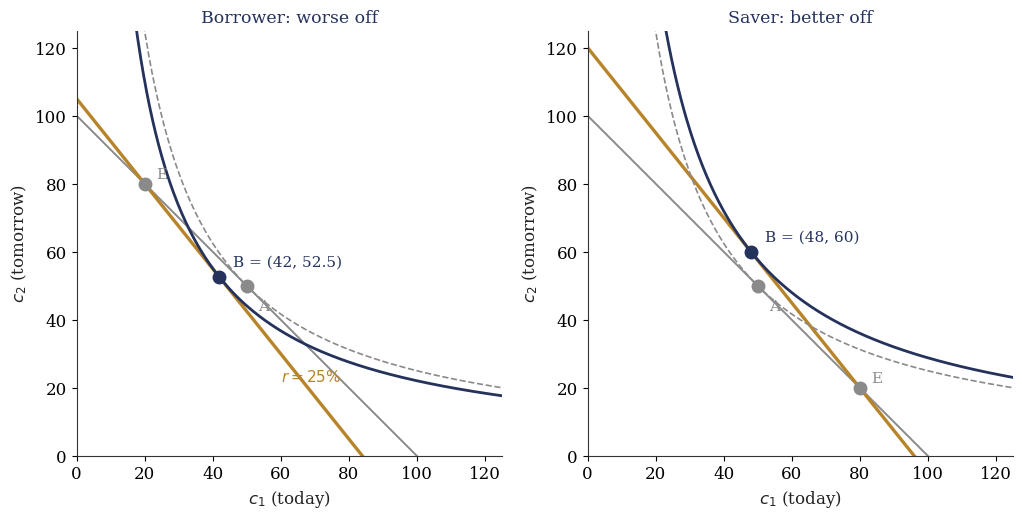

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.2))
cases = [(axes[0], (20, 80), (42, 52.5), "Borrower: worse off", 2205),
         (axes[1], (80, 20), (48, 60), "Saver: better off", 2880)]
for ax, (m1, m2), (b1, b2), title, k in cases:
    budget(ax, m1, m2, 0, color=GREY, lw=1.4)
    budget(ax, m1, m2, 0.25, color=AMBER, lw=2.4)
    ic(ax, 2500, color=GREY, lw=1.2, ls="--")
    ic(ax, k, color=NAVY, lw=2)
    dot(ax, m1, m2, "E", color=GREY, dx=8, dy=4)
    dot(ax, 50, 50, "A", color=GREY, dx=8, dy=-18)
    dot(ax, b1, b2, f"B = ({b1:g}, {b2:g})", dx=10, dy=8)
    ax.set_title(title, fontsize=12.5, color=NAVY)
    frame(ax, T1, T2, lim=125)
axes[0].annotate("$r = 25\\%$", (60, 22), color=AMBER, fontsize=11)
fig.tight_layout()
savefig(fig, "interest-rise.png")
plt.show()

## 4. A borrowing constraint (Kuhn-Tucker corner)

saved ..\slides\05_time-and-uncertainty\figs\credit-constraint.png


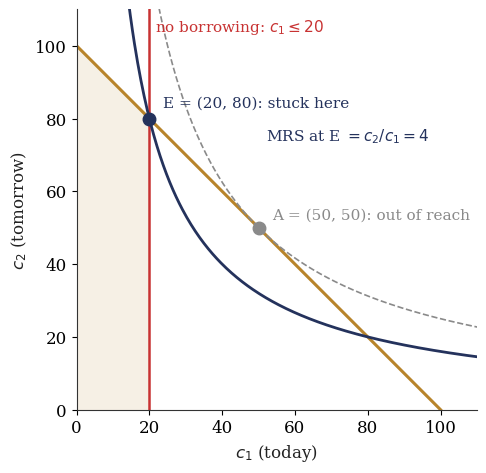

In [5]:
fig, ax = plt.subplots(figsize=(6.0, 5.2))
xs = np.linspace(0, 20, 50)
ax.fill_between(xs, 0, 100 - xs, color=AMBER, alpha=0.12, lw=0)
budget(ax, 20, 80, 0, color=AMBER, lw=2.2)
ax.axvline(20, color=RED, lw=1.8)
ax.annotate("no borrowing: $c_1 \\leq 20$", (21.5, 104), color=RED, fontsize=11)
ic(ax, 1600, color=NAVY, lw=2)
ic(ax, 2500, color=GREY, lw=1.2, ls="--")
dot(ax, 20, 80, "E = (20, 80): stuck here", dx=10, dy=8)
dot(ax, 50, 50, "A = (50, 50): out of reach", color=GREY, dx=10, dy=6)
ax.annotate("MRS at E $= c_2/c_1 = 4$", (52, 74), fontsize=11, color=NAVY)
frame(ax, T1, T2, lim=110)
savefig(fig, "credit-constraint.png")
plt.show()

## 5. Borrower meets saver: supply and demand for credit

saved ..\slides\05_time-and-uncertainty\figs\credit-market.png


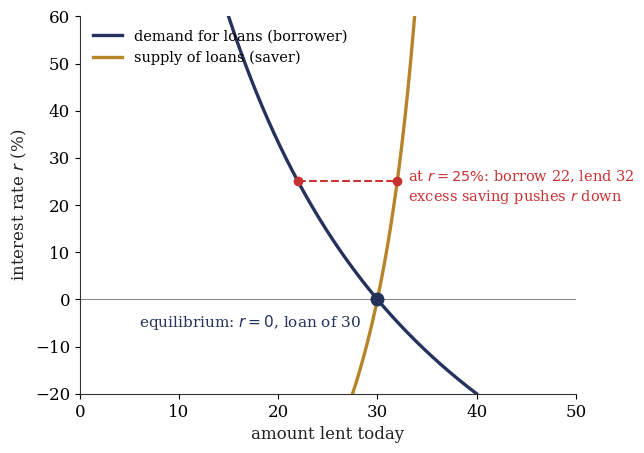

In [6]:
r = np.linspace(-0.2, 0.6, 300)
borrow = (20 + 80 / (1 + r)) / 2 - 20      # borrower's c1 minus her income today
save = 80 - (80 + 20 / (1 + r)) / 2        # saver's income today minus her c1
fig, ax = plt.subplots(figsize=(6.4, 4.9))
ax.plot(borrow, 100 * r, color=NAVY, lw=2.4, label="demand for loans (borrower)")
ax.plot(save, 100 * r, color=AMBER, lw=2.4, label="supply of loans (saver)")
dot(ax, 30, 0, "equilibrium: $r = 0$, loan of 30", dx=-12, dy=-20, ha="right")
ax.plot([22, 32], [25, 25], color=RED, lw=1.5, ls="--")
ax.plot([22, 32], [25, 25], "o", color=RED, ms=6)
ax.annotate("at $r = 25\\%$: borrow 22, lend 32\nexcess saving pushes $r$ down", (32, 25),
            textcoords="offset points", xytext=(8, -4), fontsize=10.5, color=RED, va="center")
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlim(0, 50); ax.set_ylim(-20, 60)
ax.set_xlabel("amount lent today"); ax.set_ylabel("interest rate $r$ (%)")
ax.legend(frameon=False, loc="upper left", fontsize=10.5)
savefig(fig, "credit-market.png")
plt.show()

## 6. Expected utility and the certainty equivalent

saved ..\slides\05_time-and-uncertainty\figs\expected-utility.png


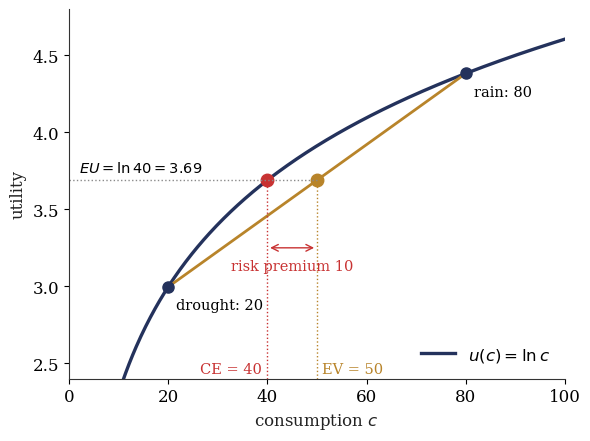

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
c = np.linspace(5, 100, 400)
ax.plot(c, np.log(c), color=NAVY, lw=2.4, label="$u(c) = \\ln c$")
ax.plot([20, 80], [np.log(20), np.log(80)], color=AMBER, lw=2)
EU = 0.5 * np.log(20) + 0.5 * np.log(80)
for x, y, lab in [(20, np.log(20), "drought: 20"), (80, np.log(80), "rain: 80")]:
    ax.plot(x, y, "o", color=NAVY, ms=8)
    ax.annotate(lab, (x, y), textcoords="offset points", xytext=(6, -16), fontsize=10.5)
ax.plot(50, EU, "o", color=AMBER, ms=9)
ax.plot(40, EU, "o", color=RED, ms=9)
ax.plot([40, 40], [2.4, EU], color=RED, lw=1, ls=":")
ax.plot([50, 50], [2.4, EU], color=AMBER, lw=1, ls=":")
ax.plot([0, 50], [EU, EU], color=GREY, lw=1, ls=":")
ax.annotate("$EU = \\ln 40 = 3.69$", (2, EU), textcoords="offset points", xytext=(0, 6), fontsize=10.5)
ax.annotate("CE = 40", (40, 2.4), textcoords="offset points", xytext=(-4, 4), ha="right", color=RED, fontsize=10.5)
ax.annotate("EV = 50", (50, 2.4), textcoords="offset points", xytext=(4, 4), color=AMBER, fontsize=10.5)
ax.annotate("", xy=(50, 3.25), xytext=(40, 3.25), arrowprops=dict(arrowstyle="<->", color=RED))
ax.annotate("risk premium 10", (45, 3.25), textcoords="offset points", xytext=(0, -16), ha="center",
            color=RED, fontsize=10.5)
ax.set_xlim(0, 100); ax.set_ylim(2.4, 4.8)
ax.set_xlabel("consumption $c$"); ax.set_ylabel("utility")
ax.legend(frameon=False, loc="lower right")
savefig(fig, "expected-utility.png")
plt.show()

## 7. Insurance in the state diagram: fair and loaded prices

saved ..\slides\05_time-and-uncertainty\figs\insurance-states.png


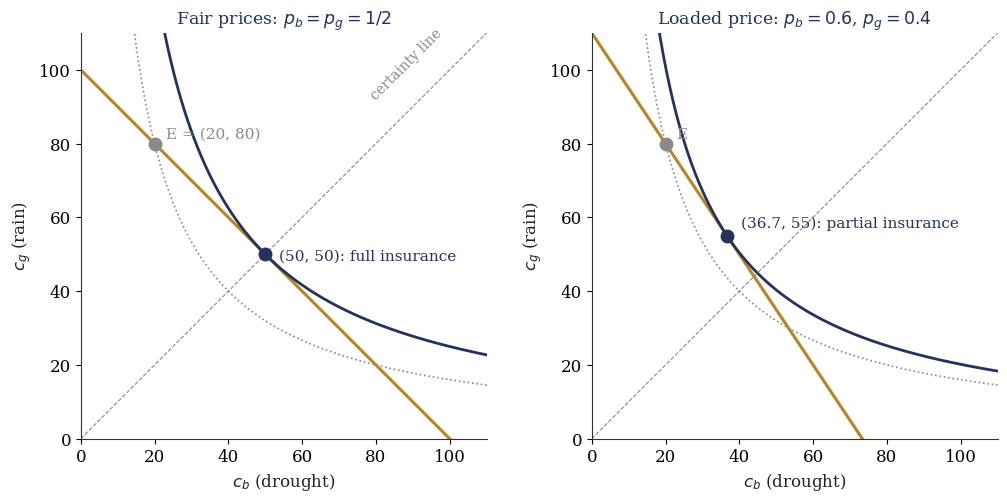

In [8]:
TB, TG = "$c_b$ (drought)", "$c_g$ (rain)"
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.0))
# fair prices 1/2, 1/2
ax = axes[0]
budget(ax, 20, 80, 0, color=AMBER, lw=2.2)
ic(ax, 2500, color=NAVY, lw=2)
ic(ax, 1600, color=GREY, lw=1.2, ls=":")
ax.plot([0, 110], [0, 110], color=GREY, lw=0.8, ls="--")
ax.annotate("certainty line", (78, 92), rotation=45, fontsize=10, color=GREY)
dot(ax, 20, 80, "E = (20, 80)", color=GREY, dx=8, dy=4)
dot(ax, 50, 50, "(50, 50): full insurance", dx=10, dy=-4)
ax.set_title("Fair prices: $p_b = p_g = 1/2$", fontsize=12.5, color=NAVY)
frame(ax, TB, TG)
# loaded: p_b = 0.6, p_g = 0.4
ax = axes[1]
pb, pg = 0.6, 0.4
W = pb * 20 + pg * 80
cb, cg = 0.5 * W / pb, 0.5 * W / pg
ax.plot([0, W / pb], [W / pg, 0], color=AMBER, lw=2.2)
ic(ax, cb * cg, color=NAVY, lw=2)
ic(ax, 1600, color=GREY, lw=1.2, ls=":")
ax.plot([0, 110], [0, 110], color=GREY, lw=0.8, ls="--")
dot(ax, 20, 80, "E", color=GREY, dx=8, dy=4)
dot(ax, cb, cg, f"({cb:.1f}, {cg:.0f}): partial insurance", dx=10, dy=6)
ax.set_title("Loaded price: $p_b = 0.6$, $p_g = 0.4$", fontsize=12.5, color=NAVY)
frame(ax, TB, TG)
fig.tight_layout()
savefig(fig, "insurance-states.png")
plt.show()

## 8. Turning the problem around: the monopoly lender

saved ..\slides\05_time-and-uncertainty\figs\monopoly-lender.png


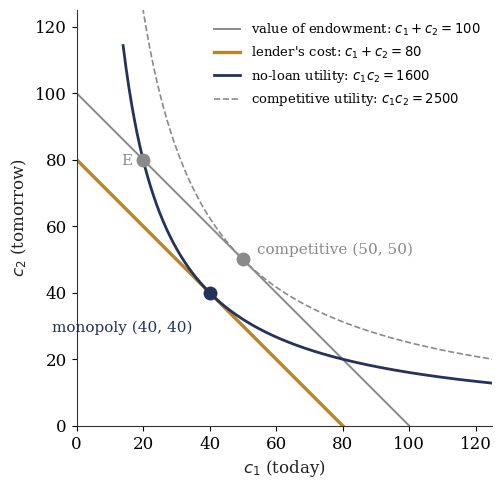

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.plot([0, 100], [100, 0], color=GREY, lw=1.4, label="value of endowment: $c_1 + c_2 = 100$")
ax.plot([0, 80], [80, 0], color=AMBER, lw=2.4, label="lender's cost: $c_1 + c_2 = 80$")
x = np.linspace(14, 125, 400)
ax.plot(x, 1600 / x, color=NAVY, lw=2, label="no-loan utility: $c_1 c_2 = 1600$")
ax.plot(x, 2500 / x, color=GREY, lw=1.2, ls="--", label="competitive utility: $c_1 c_2 = 2500$")
dot(ax, 20, 80, "E", color=GREY, dx=-8, dy=-4, ha="right")
dot(ax, 50, 50, "competitive (50, 50)", color=GREY, dx=10, dy=4)
dot(ax, 40, 40, "monopoly (40, 40)", dx=-12, dy=-28, ha="right")
ax.legend(frameon=False, fontsize=9.5, loc="upper right")
frame(ax, T1, T2, lim=125)
savefig(fig, "monopoly-lender.png")
plt.show()

## Part V, Application 1: crop insurance worked example (staged figures)

In [ ]:
# Application 1 (Part V): coffee farmer, u(c) = sqrt(c), income 144 (good) or 4 (frost),
# probability 1/2 each. Claim prices (p_b, p_g): fair (1/2, 1/2), loaded (3/5, 2/5).
# Staged figures share one frame so they can be stacked on a slide.
MG, MB = 144, 4
EC, EU0, CE = 74, 7, 49

def save_fixed(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=170)          # no tight bbox: every stage has identical size
    print(f"saved {path}")

def ce_figure(stage):
    fig, ax = plt.subplots(figsize=(5.6, 4.7))
    fig.subplots_adjust(left=0.12, right=0.97, bottom=0.13, top=0.97)
    c = np.linspace(0, 160, 500)
    ax.plot(c, np.sqrt(c), color=NAVY, lw=2.4)
    ax.annotate("$u(c) = \\sqrt{c}$", (88, np.sqrt(88)), textcoords="offset points",
                xytext=(-46, 14), color=NAVY, fontsize=12)
    ax.plot([MB, MG], [2, 12], color=AMBER, lw=2)
    ax.plot(MB, 2, "o", color=NAVY, ms=8); ax.plot(MG, 12, "o", color=NAVY, ms=8)
    ax.annotate("frost: 4", (MB, 2), textcoords="offset points", xytext=(8, -4), fontsize=11)
    ax.annotate("good: 144", (MG, 12), textcoords="offset points", xytext=(-8, 9), ha="center", fontsize=11)
    # expected income and expected utility
    ax.plot(EC, EU0, "o", color=AMBER, ms=9, zorder=6)
    ax.plot([EC, EC], [0, EU0], color=AMBER, lw=1, ls=":")
    ax.plot([0, EC], [EU0, EU0], color=GREY, lw=1, ls=":")
    ax.annotate("$EU = 7$", (1.5, EU0), textcoords="offset points", xytext=(0, 5), fontsize=11)
    ax.annotate("$E[c] = 74$", (EC, 0), textcoords="offset points", xytext=(4, 5), color=AMBER, fontsize=11)
    if stage >= 2:
        ax.plot(CE, EU0, "o", color=RED, ms=9, zorder=6)
        ax.plot([CE, CE], [0, EU0], color=RED, lw=1, ls=":")
        ax.annotate("$CE = 49$", (CE, 0), textcoords="offset points", xytext=(-4, 5), ha="right",
                    color=RED, fontsize=11)
        ax.annotate("", xy=(EC, 5.7), xytext=(CE, 5.7), arrowprops=dict(arrowstyle="<->", color=RED))
        ax.annotate("risk premium 25", (EC, 5.7), textcoords="offset points", xytext=(6, -4),
                    ha="left", color=RED, fontsize=11)
    if stage >= 3:
        ax.plot([MG, MG], [0, 12], color=GREY, lw=1, ls=":")
        ax.annotate("", xy=(MG, 3.5), xytext=(EC, 3.5), arrowprops=dict(arrowstyle="<->", color=AMBER))
        ax.annotate("fair premium 70", ((EC + MG) / 2, 3.5), textcoords="offset points", xytext=(0, 5),
                    ha="center", color=AMBER, fontsize=11)
        ax.annotate("", xy=(MG, 1.8), xytext=(CE, 1.8), arrowprops=dict(arrowstyle="<->", color=NAVY))
        ax.annotate("most he would pay 95", ((CE + MG) / 2, 1.8), textcoords="offset points", xytext=(0, 5),
                    ha="center", color=NAVY, fontsize=11)
    ax.set_xlim(0, 160); ax.set_ylim(0, 13.5)
    ax.set_xlabel("income $c$"); ax.set_ylabel("utility")
    save_fixed(fig, f"app1-ce-{stage}.png")
    plt.close(fig)

for s in (1, 2, 3):
    ce_figure(s)

def state_ic(ax, U, **kw):
    """Indifference curve (1/2) sqrt(cb) + (1/2) sqrt(cg) = U."""
    cb = np.linspace(0.5, 160, 800)
    root = 2 * U - np.sqrt(cb)
    cg = np.where(root > 0, root ** 2, np.nan)
    cg[cg > 160] = np.nan
    ax.plot(cb, cg, **kw)

def state_figure(stage):
    """stage 1: the fair price only (full cover). stage 2: adds the loaded price (partial cover)."""
    fig, ax = plt.subplots(figsize=(5.5, 5.4))
    fig.subplots_adjust(left=0.14, right=0.97, bottom=0.11, top=0.97)
    ax.plot([0, 132], [0, 132], color=GREY, lw=1, ls="--")
    ax.annotate("certainty line\n$c_b = c_g$", (114, 114), textcoords="offset points", xytext=(8, -24),
                color=GREY, fontsize=10.5)
    # budget lines through the endowment E = (4, 144)
    ax.plot([0, 148], [148, 0], color=AMBER, lw=2, label="fair prices $p_b = p_g = \\frac{1}{2}$")
    if stage >= 2:
        ax.plot([0, 100], [150, 0], color=RED, lw=2, label="loaded prices $p_b = \\frac{3}{5}$, $p_g = \\frac{2}{5}$")
    ax.legend(frameon=False, loc="upper right", fontsize=10.5, handlelength=1.6,
              bbox_to_anchor=(1.0, 1.0))
    # indifference curves: through E, and through the fair optimum
    state_ic(ax, 7.0, color=GREY, lw=1.3)
    state_ic(ax, np.sqrt(74), color=AMBER, lw=1.6)
    ax.plot(MB, MG, "o", color=NAVY, ms=9, zorder=6)
    ax.plot(74, 74, "o", color=AMBER, ms=9, zorder=6)
    if stage == 1:
        ax.annotate("$E = (4, 144)$", xy=(MB, MG), xytext=(40, 127), fontsize=11, color=NAVY,
                    arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
        ax.annotate("full insurance $(74, 74)$", (86, 72), fontsize=11, color=AMBER)
        # the fair trade: pay the premium in good weather, collect in a frost
        ax.plot([MB, MB], [MG, 74], color=AMBER, lw=1.3, ls=":")
        ax.plot([MB, 74], [74, 74], color=AMBER, lw=1.3, ls=":")
        ax.annotate("dotted: sells 70, buys 70", (16, 3), fontsize=10, color=AMBER, va="bottom")
    else:
        ax.annotate("$E$", (MB, MG), textcoords="offset points", xytext=(-3, 9), fontsize=11.5,
                    color=NAVY, ha="center")
        ax.annotate("full insurance $(74, 74)$\nsells 70, buys 70", (86, 64), fontsize=10.5, color=AMBER)
        state_ic(ax, (np.sqrt(40) + np.sqrt(90)) / 2, color=RED, lw=1.6)
        ax.plot(40, 90, "o", color=RED, ms=9, zorder=6)
        ax.annotate("partial insurance $(40, 90)$\nsells 54, buys 36", xy=(40, 90), xytext=(54, 114),
                    fontsize=10.5, color=RED, arrowprops=dict(arrowstyle="-", color=RED, lw=0.8))
        # the loaded trade
        ax.plot([MB, MB], [MG, 90], color=RED, lw=1.3, ls=":")
        ax.plot([MB, 40], [90, 90], color=RED, lw=1.3, ls=":")
        ax.annotate("dotted: the loaded trade", (14, 3), fontsize=10, color=RED, va="bottom")
    ax.set_xlim(0, 160); ax.set_ylim(0, 160)
    ax.set_xlabel("$c_b$ (income in a frost)"); ax.set_ylabel("$c_g$ (income in good weather)")
    ax.set_aspect("equal")
    save_fixed(fig, f"app1-state-{stage}.png")
    plt.close(fig)

for s in (1, 2):
    state_figure(s)
